# 05 · Decision Tree, Random Forest & Gradient Boosting

Tree models capture the non-linear patterns from the EDA (U-shaped age, the jump at the first previous contact) without scaling or bins.
Hyper-parameters are tuned with `GridSearchCV` / `RandomizedSearchCV` on the training set only, scored on ROC-AUC (lessons 13–15).

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load_data, split, linear_preprocessor, tree_preprocessor, evaluate, save_result, RANDOM_STATE

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
print('train', X_train.shape, f'yes rate {y_train.mean():.1%}')
print('test ', X_test.shape, f'yes rate {y_test.mean():.1%}')

train (36168, 18) yes rate 11.7%
test  (9043, 18) yes rate 11.7%


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import RocCurveDisplay

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
best_params = {}

## 1. Decision Tree (a single, readable tree)

In [3]:
dt_search = GridSearchCV(
    Pipeline([('prep', tree_preprocessor()),
              ('model', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))]),
    {'model__max_depth': [3, 5, 7, 10], 'model__min_samples_leaf': [20, 50, 100]},
    cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
best_params['decision_tree'] = dt_search.best_params_
print(dt_search.best_params_, '| CV ROC-AUC', round(dt_search.best_score_, 4))
proba_dt = dt_search.best_estimator_.predict_proba(X_test)[:, 1]
save_result(evaluate('Decision Tree', y_test, proba_dt))

{'model__max_depth': 10, 'model__min_samples_leaf': 20} | CV ROC-AUC 0.7671


,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Baseline (always no),0.5,0.8830,0.500,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7734,0.713,0.2876,0.6342,0.3958,0.7789
2,Decision Tree,0.5,0.8143,0.721,0.3356,0.5992,0.4303,0.7784


## 2. Random Forest (bagging many trees)

In [4]:
rf_search = RandomizedSearchCV(
    Pipeline([('prep', tree_preprocessor()),
              ('model', RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))]),
    {'model__n_estimators': [200, 400],
     'model__max_depth': [None, 10, 20],
     'model__min_samples_leaf': [1, 5, 10, 20],
     'model__max_features': ['sqrt', 0.3]},
    n_iter=8, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE).fit(X_train, y_train)
best_params['random_forest'] = rf_search.best_params_
print(rf_search.best_params_, '| CV ROC-AUC', round(rf_search.best_score_, 4))
proba_rf = rf_search.best_estimator_.predict_proba(X_test)[:, 1]
save_result(evaluate('Random Forest', y_test, proba_rf))

{'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 20} | CV ROC-AUC 0.7943


,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Baseline (always no),0.5,0.8830,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7734,0.7130,0.2876,0.6342,0.3958,0.7789
2,Decision Tree,0.5,0.8143,0.7210,0.3356,0.5992,0.4303,0.7784
3,Random Forest,0.5,0.8254,0.7416,0.3599,0.6323,0.4587,0.8039


## 3. Gradient Boosting (trees built one after another, each fixing the last one's errors)

`GradientBoostingClassifier` has no `class_weight`, so it is trained on the real class balance. That does not hurt ROC-AUC
(a ranking metric); the threshold for the yes class is tuned later in notebook 07.

In [5]:
gb_search = RandomizedSearchCV(
    Pipeline([('prep', tree_preprocessor()),
              ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    {'model__n_estimators': [100, 200, 300],
     'model__learning_rate': [0.05, 0.1],
     'model__max_depth': [2, 3, 4],
     'model__subsample': [0.8, 1.0]},
    n_iter=8, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
best_params['gradient_boosting'] = gb_search.best_params_
print(gb_search.best_params_, '| CV ROC-AUC', round(gb_search.best_score_, 4))
proba_gb = gb_search.best_estimator_.predict_proba(X_test)[:, 1]
save_result(evaluate('Gradient Boosting', y_test, proba_gb))

{'model__subsample': 0.8, 'model__n_estimators': 300, 'model__max_depth': 4, 'model__learning_rate': 0.05} | CV ROC-AUC 0.7975


,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Baseline (always no),0.5,0.8830,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7734,0.7130,0.2876,0.6342,0.3958,0.7789
2,Decision Tree,0.5,0.8143,0.7210,0.3356,0.5992,0.4303,0.7784
3,Random Forest,0.5,0.8254,0.7416,0.3599,0.6323,0.4587,0.8039
4,Gradient Boosting,0.5,0.8974,0.6180,0.6601,0.2533,0.3661,0.8057


## 4. Comparison so far

In [6]:
results = pd.read_csv('../results/metrics.csv')
results.sort_values('roc_auc', ascending=False)

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
4,Gradient Boosting,0.5,0.8974,0.6180,0.6601,0.2533,0.3661,0.8057
3,Random Forest,0.5,0.8254,0.7416,0.3599,0.6323,0.4587,0.8039
1,Logistic Regression,0.5,0.7734,0.7130,0.2876,0.6342,0.3958,0.7789
2,Decision Tree,0.5,0.8143,0.7210,0.3356,0.5992,0.4303,0.7784
0,Baseline (always no),0.5,0.8830,0.5000,0.0000,0.0000,0.0000,0.5000


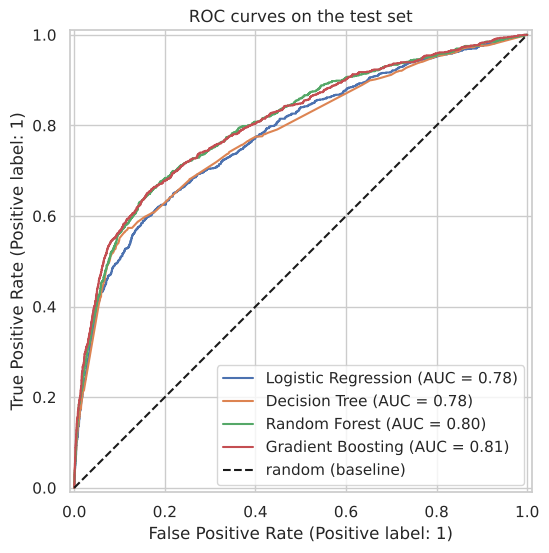

In [7]:
probas = pd.read_csv('../results/test_probas.csv')
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in [('Logistic Regression', probas['logistic_regression']), ('Decision Tree', proba_dt),
                ('Random Forest', proba_rf), ('Gradient Boosting', proba_gb)]:
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='random (baseline)')
ax.set_title('ROC curves on the test set'); ax.legend()
plt.show()

At the default 0.5 threshold the metrics differ a lot, mainly because of class weights: Gradient Boosting (no weights) is precise
but finds few subscribers, while the weighted models find more. **ROC-AUC compares the ranking fairly**, and the threshold is tuned in notebook 07.

In [8]:
probas['decision_tree'] = proba_dt
probas['random_forest'] = proba_rf
probas['gradient_boosting'] = proba_gb
probas.to_csv('../results/test_probas.csv', index=False)
with open('../results/best_params.json', 'w') as f:
    json.dump({k: {p: (v if not isinstance(v, np.generic) else v.item()) for p, v in d.items()}
               for k, d in best_params.items()}, f, indent=2)
best_params

{'decision_tree': {'model__max_depth': 10, 'model__min_samples_leaf': 20},
 'random_forest': {'model__n_estimators': 400,
  'model__min_samples_leaf': 10,
  'model__max_features': 'sqrt',
  'model__max_depth': 20},
 'gradient_boosting': {'model__subsample': 0.8,
  'model__n_estimators': 300,
  'model__max_depth': 4,
  'model__learning_rate': 0.05}}